### CatBoost hyperparameter tuning

This notebook selects the tree depth, learning rate, and regularization used by CatBoost. All trials use the same features and the same time split so their scores are directly comparable.

In [8]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.modeling import chronological_split, regression_metrics, run_experiments

data = pd.read_csv(ROOT / "data" / "train-test.csv")

### Holdout

Models learn from January through August and are tested on September and October. The later rows are not used for fitting. This is a small simulation of the final task, where the model trains on past loads and predicts November and December.

In [9]:
development, holdout = chronological_split(data, holdout_days=61)
pd.DataFrame({
    "rows": [len(development), len(holdout)],
    "date_min": [development.date.min(), holdout.date.min()],
    "date_max": [development.date.max(), holdout.date.max()],
}, index=["development", "holdout"])

,rows,date_min,date_max
development,38477,2025-01-01,2025-08-31
holdout,9523,2025-09-01,2025-10-31


### Baseline

The baseline predicts rate from distance and equipment only. It provides a reference score: CatBoost is useful only if the additional features and nonlinear relationships improve on this simpler approach.

In [10]:
equipment_columns = ["equipment_Dry Van", "equipment_Flatbed", "equipment_Reefer"]

# The squared term allows rate to bend with distance instead of forcing a straight line.
def baseline_matrix(frame):
    equipment = pd.get_dummies(frame.equipment, prefix="equipment", dtype=float)
    equipment = equipment.reindex(columns=equipment_columns, fill_value=0.0)
    return np.column_stack([np.ones(len(frame)), frame.distance, frame.distance ** 2, equipment])

x_development = baseline_matrix(development)
x_holdout = baseline_matrix(holdout)
coefficients, *_ = np.linalg.lstsq(
    x_development, development.posted_rate.to_numpy(), rcond=None
)
baseline_prediction = np.clip(x_holdout @ coefficients, 1.0, None)
pd.Series(
    regression_metrics(holdout.posted_rate, baseline_prediction),
    name="distance_equipment_baseline",
).round(3).to_frame()

,distance_equipment_baseline
rmse,640.351
mae,151.941
r2,0.824


### Search space

The first trials cover shallow and medium-depth trees with conservative learning rates. Deeper trees can learn more detailed interactions, but they can also memorize noise. Early stopping ends training when the later-period score no longer improves.

In [11]:
search_space = [
    {
        "name": "trial_01",
        "depth": 4,
        "learning_rate": 0.05,
        "l2_leaf_reg": 5.0,
        "random_strength": 0.5,
    },
    {
        "name": "trial_02",
        "depth": 6,
        "learning_rate": 0.04,
        "l2_leaf_reg": 8.0,
        "random_strength": 0.5,
    },
    {
        "name": "trial_03",
        "depth": 8,
        "learning_rate": 0.03,
        "l2_leaf_reg": 10.0,
        "random_strength": 1.0,
    },
]
pd.DataFrame(search_space)

,name,depth,learning_rate,l2_leaf_reg,random_strength
0,trial_01,4,0.05,5.0,0.5
1,trial_02,6,0.04,8.0,0.5
2,trial_03,8,0.03,10.0,1.0


### Results

RMSE is the main ranking metric because it gives extra weight to large dollar errors. MAE is the average absolute dollar error and is easier to interpret for a typical load. R-squared shows how much of the overall rate variation is explained by the model.

In [12]:
# Early stopping keeps the best iteration before holdout performance degrades.
results, _ = run_experiments(
    data,
    configs=search_space,
    holdout_days=61,
    iterations=2_500,
    early_stopping_rounds=150,
    verbose=200,
)
results.round(3)

0:	learn: 1419.4901484	test: 1469.0287597	best: 1469.0287597 (0)	total: 30.4ms	remaining: 1m 15s
200:	learn: 574.9908426	test: 634.0957695	best: 633.9910536 (198)	total: 8.43s	remaining: 1m 36s
400:	learn: 566.3506800	test: 634.9446705	best: 633.8646009 (304)	total: 17.1s	remaining: 1m 29s
Stopped by overfitting detector  (150 iterations wait)

bestTest = 633.8646009
bestIteration = 304

Shrink model to first 305 iterations.
0:	learn: 1429.9721844	test: 1479.5140573	best: 1479.5140573 (0)	total: 89.1ms	remaining: 3m 42s
200:	learn: 571.7245539	test: 633.2585403	best: 633.0004785 (184)	total: 19.6s	remaining: 3m 44s
Stopped by overfitting detector  (150 iterations wait)

bestTest = 633.0004785
bestIteration = 184

Shrink model to first 185 iterations.
0:	learn: 1442.5891966	test: 1492.1886848	best: 1492.1886848 (0)	total: 437ms	remaining: 18m 13s
200:	learn: 571.0537558	test: 635.4054975	best: 635.3062291 (196)	total: 1m 24s	remaining: 16m 2s
400:	learn: 559.9522698	test: 635.1817192	be

,name,rmse,mae,r2,best_iteration,training_seconds,depth,learning_rate,l2_leaf_reg,random_strength
0,trial_02,633.000,112.762,0.828,185,57.57,6,0.04,8.0,0.5
1,trial_01,633.865,117.759,0.827,305,19.55,4,0.05,5.0,0.5
2,trial_03,634.636,115.959,0.827,324,174.43,8,0.03,10.0,1.0


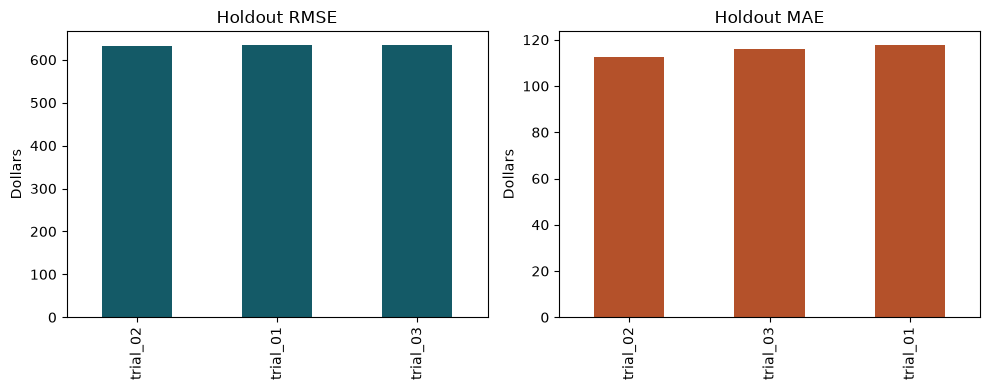

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
results.sort_values("rmse").plot.bar(
    x="name", y="rmse", legend=False, ax=axes[0], color="#145A67"
)
results.sort_values("mae").plot.bar(
    x="name", y="mae", legend=False, ax=axes[1], color="#B4512A"
)
axes[0].set(title="Holdout RMSE", xlabel="", ylabel="Dollars")
axes[1].set(title="Holdout MAE", xlabel="", ylabel="Dollars")
plt.tight_layout()

### Focused search

`trial_02` produced the lowest RMSE in the first pass. The next trials change one parameter at a time around that configuration. This keeps the comparison small and makes it clear whether depth, learning rate, or regularization caused a change.

In [14]:
focused_search_space = [
    {
        "name": "trial_04",
        "depth": 5,
        "learning_rate": 0.04,
        "l2_leaf_reg": 8.0,
        "random_strength": 0.5,
    },
    {
        "name": "trial_05",
        "depth": 7,
        "learning_rate": 0.04,
        "l2_leaf_reg": 8.0,
        "random_strength": 0.5,
    },
    {
        "name": "trial_06",
        "depth": 6,
        "learning_rate": 0.03,
        "l2_leaf_reg": 8.0,
        "random_strength": 0.5,
    },
    {
        "name": "trial_07",
        "depth": 6,
        "learning_rate": 0.05,
        "l2_leaf_reg": 8.0,
        "random_strength": 0.5,
    },
    {
        "name": "trial_08",
        "depth": 6,
        "learning_rate": 0.04,
        "l2_leaf_reg": 4.0,
        "random_strength": 0.5,
    },
    {
        "name": "trial_09",
        "depth": 6,
        "learning_rate": 0.04,
        "l2_leaf_reg": 12.0,
        "random_strength": 0.5,
    },
    {
        "name": "trial_10",
        "depth": 6,
        "learning_rate": 0.04,
        "l2_leaf_reg": 8.0,
        "random_strength": 0.2,
    },
]
pd.DataFrame(focused_search_space)

,name,depth,learning_rate,l2_leaf_reg,random_strength
0,trial_04,5,0.04,8.0,0.5
1,trial_05,7,0.04,8.0,0.5
2,trial_06,6,0.03,8.0,0.5
3,trial_07,6,0.05,8.0,0.5
4,trial_08,6,0.04,4.0,0.5
5,trial_09,6,0.04,12.0,0.5
6,trial_10,6,0.04,8.0,0.2


In [15]:
focused_results, _ = run_experiments(
    data,
    configs=focused_search_space,
    holdout_days=61,
    iterations=2_500,
    early_stopping_rounds=150,
    verbose=200,
)
focused_results.round(3)

0:	learn: 1430.4099050	test: 1479.9407086	best: 1479.9407086 (0)	total: 225ms	remaining: 9m 23s
200:	learn: 574.0596526	test: 633.8970029	best: 633.8970029 (200)	total: 35s	remaining: 6m 40s
400:	learn: 566.4757737	test: 634.0219793	best: 633.5528404 (317)	total: 1m 9s	remaining: 6m 4s
Stopped by overfitting detector  (150 iterations wait)

bestTest = 633.5528404
bestIteration = 317

Shrink model to first 318 iterations.
0:	learn: 1429.3690937	test: 1478.7673061	best: 1478.7673061 (0)	total: 249ms	remaining: 10m 23s
200:	learn: 568.1577985	test: 635.5309163	best: 635.3291855 (172)	total: 53.6s	remaining: 10m 13s
Stopped by overfitting detector  (150 iterations wait)

bestTest = 635.3291855
bestIteration = 172

Shrink model to first 173 iterations.
0:	learn: 1441.5618850	test: 1491.1525380	best: 1491.1525380 (0)	total: 205ms	remaining: 8m 31s
200:	learn: 574.7171232	test: 634.0653347	best: 634.0653347 (200)	total: 44.6s	remaining: 8m 29s
400:	learn: 565.2777191	test: 634.0764253	best: 6

,name,rmse,mae,r2,best_iteration,training_seconds,depth,learning_rate,l2_leaf_reg,random_strength
0,trial_08,633.457,112.679,0.828,222,111.24,6,0.04,4.0,0.5
1,trial_09,633.470,112.787,0.828,243,94.59,6,0.04,12.0,0.5
2,trial_04,633.553,113.825,0.828,318,81.68,5,0.04,8.0,0.5
3,trial_06,633.884,112.680,0.827,282,86.24,6,0.03,8.0,0.5
4,trial_07,634.550,115.194,0.827,144,25.72,6,0.05,8.0,0.5
5,trial_10,634.954,115.649,0.827,219,88.17,6,0.04,8.0,0.2
6,trial_05,635.329,116.262,0.827,173,85.52,7,0.04,8.0,0.5


In [16]:
all_results = (
    pd.concat([results, focused_results], ignore_index=True)
    .sort_values("rmse", ignore_index=True)
)
all_results.round(3)

,name,rmse,mae,r2,best_iteration,training_seconds,depth,learning_rate,l2_leaf_reg,random_strength
0,trial_02,633.000,112.762,0.828,185,57.57,6,0.04,8.0,0.5
1,trial_08,633.457,112.679,0.828,222,111.24,6,0.04,4.0,0.5
2,trial_09,633.470,112.787,0.828,243,94.59,6,0.04,12.0,0.5
3,trial_04,633.553,113.825,0.828,318,81.68,5,0.04,8.0,0.5
4,trial_01,633.865,117.759,0.827,305,19.55,4,0.05,5.0,0.5
5,trial_06,633.884,112.680,0.827,282,86.24,6,0.03,8.0,0.5
6,trial_07,634.550,115.194,0.827,144,25.72,6,0.05,8.0,0.5
7,trial_03,634.636,115.959,0.827,324,174.43,8,0.03,10.0,1.0
8,trial_10,634.954,115.649,0.827,219,88.17,6,0.04,8.0,0.2
9,trial_05,635.329,116.262,0.827,173,85.52,7,0.04,8.0,0.5
